# Weapon & Warframe data exploration

Poking around the same data the calculator runs on (`src/data/*.json`, built from `@wfcd/items` by `scripts/build-data.mjs`).
Rerun `node scripts/build-data.mjs` first if the item data got updated.

Numbers here are **base stats** (no mods, rank 30 for frames where the data has it), one row per attack.

In [8]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# I keep the notebook in notebooks/, the data lives next door in src/data
DATA = Path('..') / 'src' / 'data'
weapons_raw = json.loads((DATA / 'weapons.json').read_text())
frames_raw = json.loads((DATA / 'warframes.json').read_text())
mods_raw = json.loads((DATA / 'mods.json').read_text())

pd.set_option('display.max_rows', 60)
pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (9, 4.5)
print(f'{len(weapons_raw)} weapons, {len(frames_raw)} warframes, {len(mods_raw)} mods')

603 weapons, 119 warframes, 927 mods


## Weapons: one row per attack

In [9]:
PHYSICAL = {'impact', 'puncture', 'slash'}

rows = []
for weapon in weapons_raw:
    attacks = weapon['attacks']
    # the "main" attack: first direct one that isn't the Incarnon form and actually does damage
    main = next((a for a in attacks if not a['isAoE'] and 'incarnon' not in a['name'].lower() and a['damage']), attacks[0])
    for attack in attacks:
        damage = attack['damage']
        total = sum(damage.values())
        physical = sum(v for k, v in damage.items() if k in PHYSICAL)
        rows.append({
            'weapon': weapon['name'],
            'category': weapon['category'],
            'type': weapon['type'],
            'trigger': weapon.get('trigger'),
            'attack': attack['name'],
            'is_main': attack is main,
            'is_incarnon': 'incarnon' in attack['name'].lower(),
            'is_aoe': attack['isAoE'],
            'is_beam': bool(attack.get('continuous')),
            'total_damage': total,
            'physical_share': physical / total if total else 0,
            'dominant_type': max(damage, key=damage.get) if damage else None,
            'crit_chance': attack['critChance'],
            'crit_mult': attack['critMultiplier'],
            'status_chance': attack['statusChance'],
            'fire_rate': attack['fireRate'],
            'multishot': attack.get('multishot', weapon.get('multishot', 1)),
            'magazine': weapon.get('magazineSize'),
            'reload': weapon.get('reloadTime'),
            'riven_dispo': weapon.get('rivenDisposition'),
        })
attacks = pd.DataFrame(rows)
main = attacks[attacks.is_main].copy()
incarnon = attacks[attacks.attack.str.fullmatch('Incarnon Form', case=False)].copy()
print(f'{len(attacks)} attacks, {len(main)} main attacks, {len(incarnon)} Incarnon forms')
main.head()

1802 attacks, 603 main attacks, 63 Incarnon forms


,weapon,category,type,trigger,attack,is_main,is_incarnon,is_aoe,is_beam,total_damage,physical_share,dominant_type,crit_chance,crit_mult,status_chance,fire_rate,multishot,magazine,reload,riven_dispo
0,Acceltra,Primary,Rifle,Auto,Rocket Impact,True,False,False,False,35.0,1.0,impact,0.32,2.8,0.06,12.000,1,48.0,2.0,0.65
2,Acceltra Prime,Primary,Rifle,Auto,Rocket Impact,True,False,False,False,44.0,1.0,impact,0.34,3.0,0.18,10.000,1,48.0,1.6,0.55
4,Ack & Brunt,Melee,Melee,None,Normal Attack,True,False,False,False,149.0,1.0,slash,0.20,2.0,0.10,0.833,1,NaN,NaN,1.35
10,Acrid,Secondary,Pistol,Semi,Normal Attack,True,False,False,False,43.0,0.0,toxin,0.05,2.0,0.10,5.000,1,15.0,1.2,1.33
11,Aegrit,Secondary,Throwing,Active,Direct Hit,True,False,False,False,9.0,1.0,impact,0.37,1.9,0.19,2.000,1,2.0,1.3,1.00


In [10]:
# how the arsenal splits up
main.groupby(['category', 'type']).size().rename('weapons').to_frame().sort_values('weapons', ascending=False)

weapons
category  type                 
Melee     Melee             237
Secondary Pistol            130
Primary   Rifle             116
          Shotgun            37
          Bow                19
          Sniper             16
Secondary Dual Pistols       14
          Throwing           13
Primary   Launcher           11
Melee     Rifle              10

## Crit chance buckets
Same buckets as the question earlier: under 10%, 10–19%, 20–29%, 30–39%, 40%+.

In [11]:
BINS = [0, 0.1, 0.2, 0.3, 0.4, 10]
LABELS = ['<10%', '10–19%', '20–29%', '30–39%', '40%+']

def buckets(series):
    counts = pd.cut(series, BINS, labels=LABELS, right=False).value_counts().reindex(LABELS)
    return pd.DataFrame({'count': counts, 'share': (counts / counts.sum() * 100).round(1)})

pd.concat({'stock main attack': buckets(main.crit_chance), 'Incarnon form': buckets(incarnon.crit_chance)}, axis=1)

stock main attack       Incarnon form      
                        count share         count share
crit_chance                                            
<10%                       88  14.6             0   0.0
10–19%                    188  31.2            11  17.5
20–29%                    217  36.0            26  41.3
30–39%                     92  15.3            19  30.2
40%+                       18   3.0             7  11.1

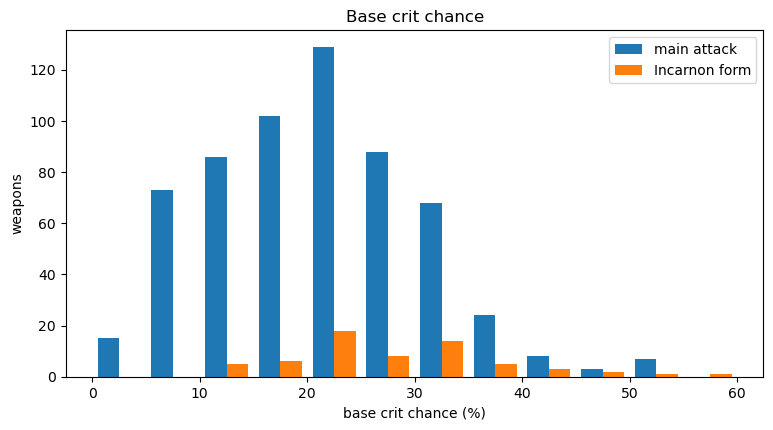

In [12]:
fig, ax = plt.subplots()
ax.hist([main.crit_chance * 100, incarnon.crit_chance * 100], bins=range(0, 61, 5), label=['main attack', 'Incarnon form'])
ax.set_xlabel('base crit chance (%)'); ax.set_ylabel('weapons'); ax.legend(); ax.set_title('Base crit chance')
plt.show()

## Crit vs status
A rough lean: crit weight = chance × (multiplier − 1), compared against status chance.

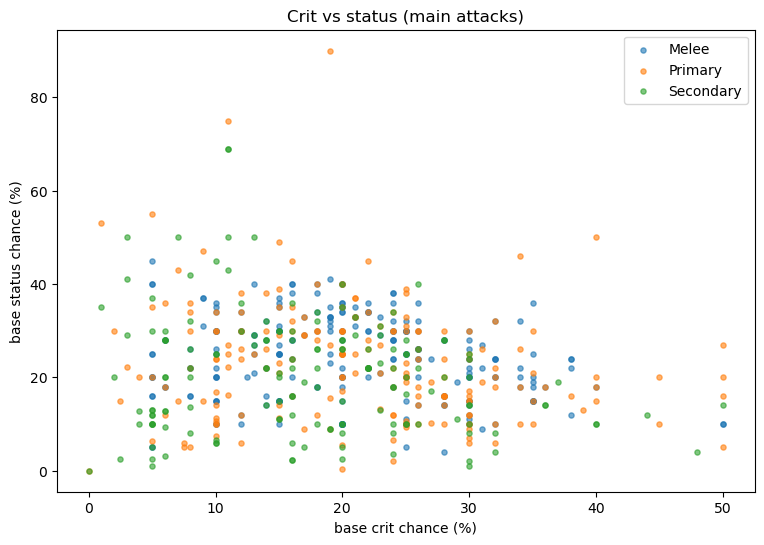

lean,status,hybrid,crit
category,,,
Melee,90,87,70
Primary,59,70,70
Secondary,53,65,39


In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
for category, group in main.groupby('category'):
    ax.scatter(group.crit_chance * 100, group.status_chance * 100, s=14, alpha=0.6, label=category)
ax.set_xlabel('base crit chance (%)'); ax.set_ylabel('base status chance (%)'); ax.legend(); ax.set_title('Crit vs status (main attacks)')
plt.show()

main['crit_weight'] = main.crit_chance * (main.crit_mult - 1)
main['lean'] = pd.cut(main.crit_weight - main.status_chance, [-10, -0.1, 0.1, 10], labels=['status', 'hybrid', 'crit'])
main.groupby(['category', 'lean'], observed=False).size().unstack()

## Damage types

In [14]:
# which damage type each weapon leans on most, and how many have innate elements at all
print('weapons with some innate elemental damage:', (main.physical_share < 1).sum(), 'of', len(main))
main.dominant_type.value_counts().to_frame('weapons')

weapons with some innate elemental damage: 138 of 603


,weapons
dominant_type,
slash,216
puncture,140
impact,127
electricity,33
heat,21
radiation,17
toxin,13
corrosive,10
viral,8


## A rough unmodded DPS proxy
damage × fire rate × multishot × average crit, ignoring reloads, status and everything mods do. It's only good for spotting
which weapons have strong bones, the leaderboard is the real ranking.

In [15]:
main['raw_dps'] = main.total_damage * main.fire_rate * main.multishot * (1 + main.crit_chance * (main.crit_mult - 1))
main.sort_values('raw_dps', ascending=False).groupby('category').head(5)[
    ['weapon', 'category', 'type', 'total_damage', 'fire_rate', 'multishot', 'crit_chance', 'crit_mult', 'raw_dps']
].round(2)

,weapon,category,type,total_damage,fire_rate,multishot,crit_chance,crit_mult,raw_dps
526,Exergis,Primary,Shotgun,540.0,3.33,3,0.08,1.4,5567.23
1612,Tigris Prime,Primary,Shotgun,195.0,2.00,8,0.10,2.0,3432.00
1380,Shadow Clones,Melee,Melee,1500.0,2.00,1,0.05,1.2,3030.00
1381,Shadow Clones Prime,Melee,Melee,1500.0,2.00,1,0.05,1.2,3030.00
1477,Strun Prime,Primary,Shotgun,54.0,3.33,12,0.24,2.2,2779.30
544,Felarx,Primary,Shotgun,190.0,3.00,4,0.20,2.0,2736.00
1320,Sancti Tigris,Primary,Shotgun,210.0,2.00,6,0.15,1.5,2709.00
1654,Twin Rogga,Secondary,Pistol,47.0,2.50,15,0.10,2.0,1938.75
31,Akbronco Prime,Secondary,Dual Pistols,50.0,4.33,7,0.06,2.0,1606.43
30,Akbronco,Secondary,Dual Pistols,42.0,5.00,7,0.06,2.0,1558.20


## Riven disposition

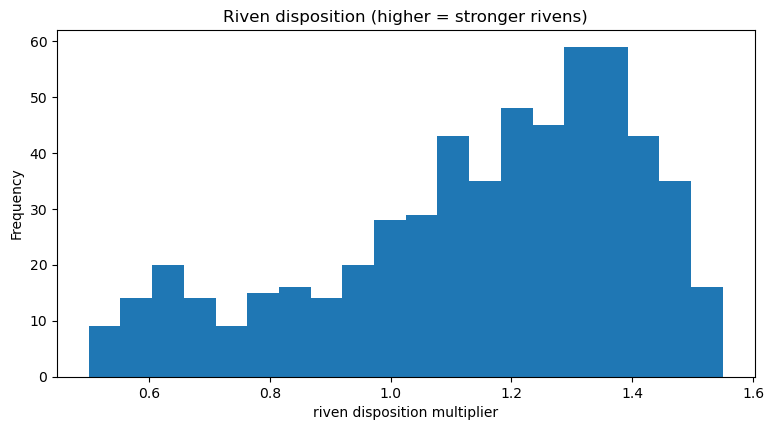

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Melee,226.0,1.15,0.24,0.6,1.0,1.2,1.35,1.50
Primary,196.0,1.12,0.25,0.5,1.0,1.2,1.30,1.55
Secondary,149.0,1.15,0.26,0.5,1.0,1.2,1.35,1.53


In [16]:
fig, ax = plt.subplots()
main.riven_dispo.dropna().plot.hist(bins=20, ax=ax)
ax.set_xlabel('riven disposition multiplier'); ax.set_title('Riven disposition (higher = stronger rivens)')
plt.show()
main.groupby('category').riven_dispo.describe().round(2)

## Warframes
Health, shields and armor are the data's values; energy is the rank 0 number (most frames get +50 by rank 30, see `src/data/archonShards.ts` for the exceptions).

In [17]:
frames = pd.DataFrame([{
    'frame': f['name'],
    'base': f['name'].replace(' Prime', '').replace(' Umbra', ''),
    'variant': 'Prime' if f['name'].endswith('Prime') else 'Umbra' if f['name'].endswith('Umbra') else 'base',
    'health': f['health'], 'shield': f['shield'], 'armor': f['armor'], 'energy': f['energy'],
    'aura_slots': len(f.get('auraPolarities') or []) or 1,
    'polarities': len(f.get('polarities') or []),
} for f in frames_raw])
# a rough effective health: armor reduces health damage by armor / (armor + 300), shields get no armor
frames['ehp'] = frames.health / (1 - frames.armor / (frames.armor + 300)) + frames.shield
frames.describe().round(1)

,health,shield,armor,energy,aura_slots,polarities,ehp
count,119.0,119.0,119.0,119.0,119.0,119.0,119.0
mean,380.6,333.3,237.7,159.9,1.0,2.6,1060.3
std,287.4,212.2,157.4,46.6,0.1,0.7,625.1
min,150.0,0.0,105.0,0.0,1.0,1.0,423.0
25%,270.0,235.0,135.0,140.0,1.0,2.0,686.5
50%,270.0,270.0,185.0,175.0,1.0,2.0,891.5
75%,400.0,455.0,302.5,185.5,1.0,3.0,1103.5
max,2215.0,1380.0,1000.0,250.0,2.0,4.0,3987.0


In [18]:
frames.sort_values('ehp', ascending=False).head(10)[['frame', 'health', 'shield', 'armor', 'energy', 'ehp']].round(0)

,frame,health,shield,armor,energy,ehp
44,Inaros Prime,2215,0,240,140,3987.0
43,Inaros,2110,0,240,100,3798.0
102,Valkyr Prime,650,135,1000,175,2952.0
51,Kullervo,1005,0,550,175,2848.0
34,Grendel Prime,1095,95,400,200,2650.0
101,Valkyr,650,135,855,100,2638.0
83,Qorvex,600,200,875,150,2550.0
33,Grendel,1095,95,370,175,2540.0
53,Lavos Prime,600,310,575,0,2060.0
70,Nidus Prime,825,0,425,140,1994.0


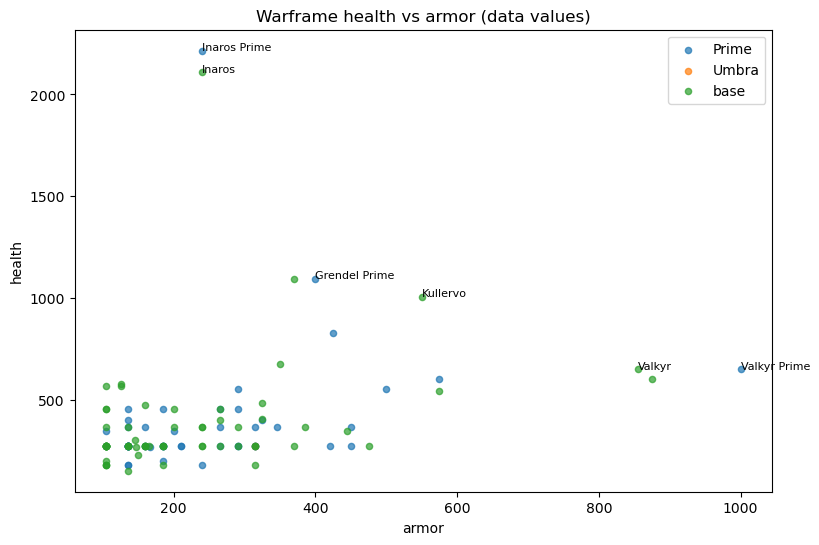

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))
for variant, group in frames.groupby('variant'):
    ax.scatter(group.armor, group.health, s=20, alpha=0.7, label=variant)
for _, row in frames.nlargest(6, 'ehp').iterrows():
    ax.annotate(row.frame, (row.armor, row.health), fontsize=8)
ax.set_xlabel('armor'); ax.set_ylabel('health'); ax.legend(); ax.set_title('Warframe health vs armor (data values)')
plt.show()

In [20]:
# what the Prime / Umbra version adds over the base frame
pairs = frames[frames.variant != 'base'].merge(frames[frames.variant == 'base'], on='base', suffixes=('', '_base'))
for stat in ['health', 'shield', 'armor', 'energy']:
    pairs[f'{stat}_gain'] = pairs[stat] - pairs[f'{stat}_base']
pairs[['frame', 'health_gain', 'shield_gain', 'armor_gain', 'energy_gain']].sort_values('armor_gain', ascending=False).head(15)

,frame,health_gain,shield_gain,armor_gain,energy_gain
44,Valkyr Prime,0,0,145,75
13,Garuda Prime,0,0,105,80
5,Chroma Prime,0,0,80,25
0,Ash Prime,0,95,80,0
28,Mirage Prime,0,110,80,0
9,Excalibur Prime,0,0,75,75
31,Nidus Prime,150,0,75,40
10,Excalibur Umbra,0,0,75,75
39,Saryn Prime,0,0,75,25
47,Voruna Prime,0,0,65,30


## Mods at a glance

In [21]:
mods = pd.DataFrame([{'name': m['name'], 'type': m['type'], 'rarity': m.get('rarity'), 'max_rank': m.get('fusionLimit'),
                      'set': m.get('modSet'), 'exilus': m.get('isExilus')} for m in mods_raw])
mods.groupby(['type', 'rarity']).size().unstack(fill_value=0)

rarity,Common,Legendary,Rare,Uncommon
type,,,,
Melee Mod,17,12,70,34
Primary Mod,14,14,114,36
Secondary Mod,10,14,76,31
Shotgun Mod,8,14,37,30
Warframe Mod,20,15,296,65


## Ideas for later
- join the leaderboard (`public/leaderboard.json`) to see which base stats actually predict a high modded score
- Incarnon perks live in `src/data/incarnon.ts`, not JSON. exporting them would let this include the perk crit bonuses
- per-faction: how often each element is a weakness vs the weapons that carry it innately